# Broader overlap distributions at fixed $h=0.15$

These are measured pure GFMC overlap histograms for periodic kagome $L=4$
($N=48$). Only complete ensembles with eight disorders and two repeats per
disorder are shown. The same disorder IDs 60000–60007 have equal weight at every
field and for both guides; no disorder is selected by its observed broadness.
The earlier [exact $L=2$ and guide-MCMC comparisons](preliminary_disorder_overlap.html)
remain available in the companion report.

The Hamiltonian is
$$H=\sum_{\langle ij\rangle}K_{ij}Z_iZ_j-0.15\sum_iZ_i-\Gamma\sum_iX_i,$$
with iid antiferromagnetic bonds $K_{ij}\sim U(0.5,1.5)$, stored as $J_{ij}=-K_{ij}$.
NumPy `default_rng(SeedSequence([20261027,L,sample_id,1]))` draws bonds in the
periodic lattice bond-list order. Quenched bonds are reused across all fields,
guides, and seeds for each size and disorder ID.

Each run uses four independently branching populations with 512 walkers each,
equilibration and forward times 16, and eight cycles. Descendant-weighted
configurations are pooled equally across cycles; all six cross-population pairs
give $q=N^{-1}\sum_i s_i t_i$. Repeats are averaged within each disorder first.
The higher-field histograms are deterministic replays of frozen production
trajectories. Their $q,q^2$, and connected spectra must match production to
$10^{-12}$. The $\Gamma=0.60,0.65$ histograms reuse the earlier verified measurements.

$P(q)$ denotes probability mass at each allowed overlap; connecting lines are
visual aids. Capped bars give $\pm s_J/\sqrt8$ pointwise in $q$. Width bars use a
delete-one-disorder jackknife. These errors exclude mixing and projection bias.
All ancestry alarms retain equal disorder weight. **The projections remain
preliminary** pending population, forward-time and starting-state sensitivity.
Broadening alone does not establish glassiness, a transition, or finite-size drift.
Computation, checks, plotting and notebook execution take place on AutoDL.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib, json
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/kagome').is_dir())
folder=root/'data/kagome/ltfim_disorder_scaling_v1/broader_histograms/20261103T035100Z_preview'
import sys
sys.path.insert(0,str(folder/'sources'))
from transformer_qmc.production_protocol import identity
from transformer_qmc.disorder_scaling import observables
load=lambda name:json.loads((folder/name).read_text())
protocol=load('protocol.json')
assert protocol['h']==.15 and not load('complete.json')['failures']
for name,expected in protocol['input_sha256'].items():
    assert hashlib.sha256((folder/name).read_bytes()).hexdigest()==expected,name
rows=load('projected_distributions.json')['rows']
assert len(rows)==load('complete.json')['projected']
groups=defaultdict(list)
for r in rows:
    t=r['task']; assert t['L']==4 and t['audit']=='main' and r['replay_verified']
    q=np.array(r['q_grid']);p=np.array(r['mass'])
    assert (p>=0).all()
    np.testing.assert_allclose(p.sum(),1,atol=1e-12)
    np.testing.assert_allclose([q@p,q**2@p],[r['q'],r['q2']],atol=1e-12,rtol=0)
    original=load('production/runs/'+identity(t)[:24]+'.json')
    np.testing.assert_allclose([r['q'],r['q2']],[original['q'],original['q2']],atol=1e-12,rtol=0)
    np.testing.assert_allclose(r['spectrum'],original['spectrum'],atol=1e-12,rtol=0)
    assert r['provenance']['model_sha256']==original['provenance']['model_sha256']
    assert hashlib.sha256((folder/r['raw_file']).read_bytes()).hexdigest()==r['raw_sha256']
    with np.load(folder/r['raw_file']) as raw:
        weights=raw['counts']/t['walkers']
        r['uniform_m']=float((weights*raw['tags'].mean(3)).sum(2).mean())
        spins=raw['tags'].astype(float)
        m=np.einsum('crw,crwn->crn',weights,spins)
        pair=np.einsum('crw,crwi,crwj->crij',weights,spins,spins)
        reconstructed=observables(m.mean(0),pair.mean(0),t['L'])
        np.testing.assert_allclose([q@p,q**2@p],[reconstructed['q'],reconstructed['q2']],atol=1e-12,rtol=0)
        np.testing.assert_allclose(r['spectrum'],reconstructed['spectrum'],atol=1e-12,rtol=0)
    groups[(t['gamma'],t['kind'])].append(r)
def width(a):
    mean=a.mean(0)
    return np.sqrt(max(0,float(q*q@mean-(q@mean)**2)))
def jackknife(a,stat):
    x=np.array([stat(np.delete(a,i,axis=0)) for i in range(8)])
    return float(np.sqrt(7/8*np.sum((x-x.mean())**2)))
curves={};summary=[]
for (g,kind),rs in sorted(groups.items()):
    assert len(rs)==16
    byid={sid:[r for r in rs if r['task']['sample_id']==sid] for sid in range(60000,60008)}
    assert all(sorted(r['task']['repeat'] for r in sample)==[0,1] for sample in byid.values())
    values=np.array([np.mean([r['mass'] for r in sample],axis=0) for sample in byid.values()])
    magnet=np.array([np.mean([r['uniform_m'] for r in sample]) for sample in byid.values()])
    q=np.array(rs[0]['q_grid']);mean=values.mean(0);se=values.std(0,ddof=1)/np.sqrt(8)
    assert all(np.array_equal(q,r['q_grid']) for r in rs)
    curves[(g,kind)]=(q,values,mean,se)
    m=values@q;v=values@(q*q)-m*m
    within=float(v.mean());between=float(m.var())
    np.testing.assert_allclose(within+between,width(values)**2,atol=1e-12)
    negative=values[:,q<0].sum(1)
    summary.append(dict(L=4,gamma=g,kind=kind,width=float(width(values)),width_se=jackknife(values,width),
        mean_q=float(m.mean()),mean_q_se=float(m.std(ddof=1)/np.sqrt(8)),peak_q=float(q[mean.argmax()]),
        negative_mass=float(negative.mean()),negative_mass_se=float(negative.std(ddof=1)/np.sqrt(8)),
        uniform_m=float(magnet.mean()),uniform_m_se=float(magnet.std(ddof=1)/np.sqrt(8)),
        within_disorder_variance=within,between_disorder_variance=between,
        ancestry_alarms=sum(r['ancestry_alarm'] for r in rs),runs=16))
figures=folder/'figures';figures.mkdir(exist_ok=True)
def finish(fig,name):
    fig.tight_layout()
    for suffix in ['png','pdf']:
        fig.savefig(figures/(name+'.'+suffix),dpi=180,bbox_inches='tight')
    plt.show()
names={'jastrow':'Jastrow','rbm_2':'RBM (alpha=2)'}
colors={.6:'#440154',.65:'#3b528b',.7:'#21918c',.85:'#e08b20',1.:'#cc3311'}
print('Frozen inputs:',protocol['created_utc'])
print('Measurement capture:',protocol.get('measurement_snapshot_utc',protocol['created_utc']))
print('Verified histogram runs:',len(rows),'| h=0.15 | eight equally weighted disorders per curve')
for item in protocol['coverage']:
    if (item['gamma'],item['kind']) not in curves:print('Histogram ensemble pending:',item)


Frozen inputs: 2026-11-03T03:36:14.755475+00:00
Measurement capture: 2026-11-03T03:49:58.555724+00:00
Verified histogram runs: 112 | h=0.15 | eight equally weighted disorders per curve
Histogram ensemble pending: {'L': 4, 'gamma': 0.7, 'kind': 'rbm_2', 'runs': 16, 'complete': True}
Histogram ensemble pending: {'L': 4, 'gamma': 0.85, 'kind': 'rbm_2', 'runs': 16, 'complete': True}
Histogram ensemble pending: {'L': 4, 'gamma': 1.0, 'kind': 'rbm_2', 'runs': 10, 'complete': False}


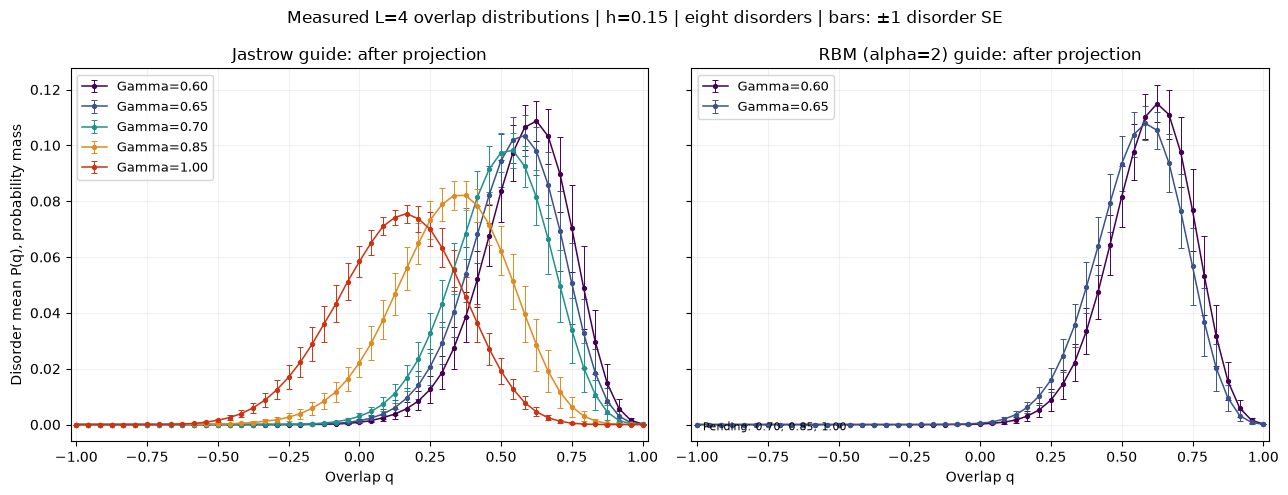

In [2]:
fig,axes=plt.subplots(1,2,figsize=(13,5),sharex=True,sharey=True)
for ax,kind in zip(axes,['jastrow','rbm_2']):
    for (g,k),(q,values,mean,se) in sorted(curves.items()):
        if k!=kind:continue
        ax.errorbar(q,mean,yerr=se,fmt='o-',ms=2.8,lw=1.1,elinewidth=.7,capsize=2,
                    capthick=.7,color=colors[g],label=f'Gamma={g:.2f}')
    ax.set(title=names[kind]+' guide: after projection',xlabel='Overlap q',xlim=(-1.02,1.02))
    pending=[g for g in protocol['fields'] if (g,kind) not in curves]
    if pending:
        ax.text(.02,.03,'Pending: '+', '.join(f'{g:.2f}' for g in pending),transform=ax.transAxes,fontsize=8)
    ax.grid(alpha=.18);ax.legend(fontsize=9)
axes[0].set_ylabel('Disorder mean P(q), probability mass')
fig.suptitle('Measured L=4 overlap distributions | h=0.15 | eight disorders | bars: ±1 disorder SE')
finish(fig,'broader_distributions')


The following diagnostics use the same
histograms and raw descendant measurements. The width is that of the
disorder-averaged distribution. Its variance splits into the average
within-disorder variance and the variance of disorder means; this distinguishes
changes within samples from a spread of sample centers. Uniform magnetization
and negative-overlap mass are displayed alongside width because the fixed
longitudinal field breaks spin-inversion symmetry.

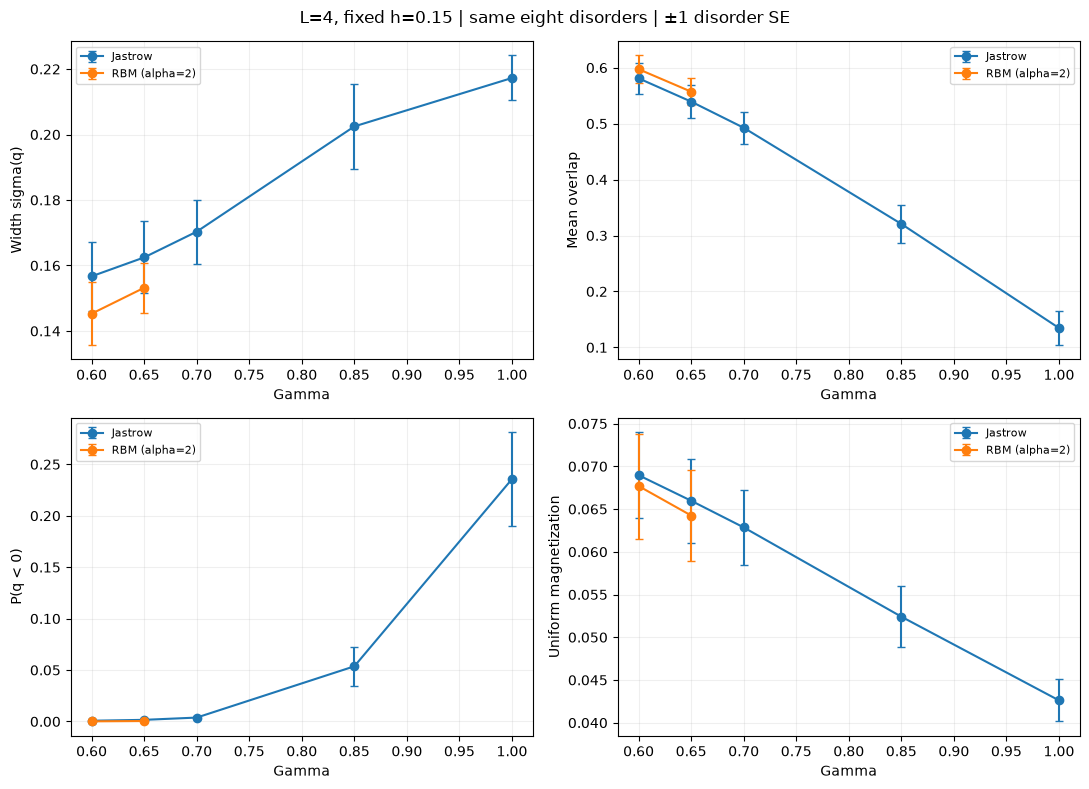

| Gamma | Guide | Width ± SE | Mean q | P(q<0) | Uniform m | Within variance | Between variance | Ancestry alarms / 16 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 0.60 | Jastrow | 0.1567 ± 0.0105 | 0.5809 | 0.00074 | 0.0690 | 0.01914 | 0.00542 | 6 |
| 0.60 | RBM (alpha=2) | 0.1453 ± 0.0096 | 0.5973 | 0.00014 | 0.0677 | 0.01690 | 0.00421 | 8 |
| 0.65 | Jastrow | 0.1625 ± 0.0110 | 0.5393 | 0.00160 | 0.0660 | 0.02040 | 0.00600 | 5 |
| 0.65 | RBM (alpha=2) | 0.1532 ± 0.0077 | 0.5571 | 0.00043 | 0.0642 | 0.01927 | 0.00421 | 14 |
| 0.70 | Jastrow | 0.1703 ± 0.0098 | 0.4926 | 0.00380 | 0.0629 | 0.02336 | 0.00566 | 5 |
| 0.85 | Jastrow | 0.2025 ± 0.0129 | 0.3206 | 0.05365 | 0.0524 | 0.03303 | 0.00796 | 6 |
| 1.00 | Jastrow | 0.2173 ± 0.0069 | 0.1346 | 0.23566 | 0.0426 | 0.04079 | 0.00641 | 5 |

Verified frozen input hashes, raw measurement hashes, replayed moments and spectra, and variance decomposition.


In [3]:
fig,axes=plt.subplots(2,2,figsize=(11,8))
for ax,key,error,label in zip(axes.flat,['width','mean_q','negative_mass','uniform_m'],
        ['width_se','mean_q_se','negative_mass_se','uniform_m_se'],
        ['Width sigma(q)','Mean overlap','P(q < 0)','Uniform magnetization']):
    for kind,color in [('jastrow','tab:blue'),('rbm_2','tab:orange')]:
        data=[r for r in summary if r['kind']==kind]
        ax.errorbar([r['gamma'] for r in data],[r[key] for r in data],yerr=[r[error] for r in data],
                    fmt='o-',capsize=3,color=color,label=names[kind])
    ax.set(xlabel='Gamma',ylabel=label);ax.grid(alpha=.2);ax.legend(fontsize=8)
fig.suptitle('L=4, fixed h=0.15 | same eight disorders | ±1 disorder SE')
finish(fig,'broader_distribution_diagnostics')
headers=['Gamma','Guide','Width ± SE','Mean q','P(q<0)','Uniform m','Within variance','Between variance','Ancestry alarms / 16']
table=[]
for r in summary:
    table.append([f"{r['gamma']:.2f}",names[r['kind']],f"{r['width']:.4f} ± {r['width_se']:.4f}",
                  f"{r['mean_q']:.4f}",f"{r['negative_mass']:.5f}",f"{r['uniform_m']:.4f}",
                  f"{r['within_disorder_variance']:.5f}",f"{r['between_disorder_variance']:.5f}",r['ancestry_alarms']])
display(Markdown('| '+' | '.join(headers)+' |\n| '+' | '.join(['---']*len(headers))+' |\n'+
    '\n'.join('| '+' | '.join(map(str,r))+' |' for r in table)))
(folder/'summary.json').write_text(json.dumps(dict(created_utc=protocol['created_utc'],
    measurement_snapshot_utc=protocol.get('measurement_snapshot_utc'),
    complete_ensembles=summary,production_coverage=protocol['coverage'],
    measured_coverage=protocol.get('measured_coverage'),ground_state_qualified=False),indent=2)+'\n')
print('Verified frozen input hashes, raw measurement hashes, replayed moments and spectra, and variance decomposition.')


In [4]:
# Paired field comparisons use the same eight disorders in the same order.
paired=[]
for kind in ['jastrow','rbm_2']:
    base=curves[(.6,kind)][1]
    for (g,k),(q,values,mean,se) in sorted(curves.items()):
        if k!=kind or g<=.6:continue
        change=width(values)-width(base)
        leave=np.array([width(np.delete(values,i,axis=0))-width(np.delete(base,i,axis=0)) for i in range(8)])
        error=float(np.sqrt(7/8*np.sum((leave-leave.mean())**2)))
        within=lambda a:a@(q*q)-(a@q)**2
        delta=within(values)-within(base)
        paired.append(dict(kind=kind,gamma=g,reference_gamma=.6,width_change=float(change),
            paired_width_change_se=error,width_ratio=float(width(values)/width(base)),
            within_variance_change=float(delta.mean()),within_variance_change_se=float(delta.std(ddof=1)/np.sqrt(8))))
headers=['Guide','Gamma','Width change from 0.60 ± paired SE','Width ratio','Within-disorder variance change ± SE']
display(Markdown('| '+' | '.join(headers)+' |\n| '+' | '.join(['---']*len(headers))+' |\n'+
    '\n'.join('| '+' | '.join([names[r['kind']],f"{r['gamma']:.2f}",
        f"{r['width_change']:.4f} ± {r['paired_width_change_se']:.4f}",f"{r['width_ratio']:.3f}",
        f"{r['within_variance_change']:.5f} ± {r['within_variance_change_se']:.5f}"])+' |' for r in paired)))
saved=json.loads((folder/'summary.json').read_text());saved['paired_field_comparisons']=paired
(folder/'summary.json').write_text(json.dumps(saved,indent=2)+'\n')


| Guide | Gamma | Width change from 0.60 ± paired SE | Width ratio | Within-disorder variance change ± SE |
| --- | --- | --- | --- | --- |
| Jastrow | 0.65 | 0.0058 ± 0.0023 | 1.037 | 0.00126 ± 0.00036 |
| Jastrow | 0.70 | 0.0136 ± 0.0052 | 1.087 | 0.00422 ± 0.00114 |
| Jastrow | 0.85 | 0.0458 ± 0.0137 | 1.292 | 0.01389 ± 0.00210 |
| Jastrow | 1.00 | 0.0606 ± 0.0142 | 1.387 | 0.02166 ± 0.00308 |
| RBM (alpha=2) | 0.65 | 0.0079 ± 0.0044 | 1.055 | 0.00237 ± 0.00095 |

7963

The fine scan retains the full
$L=4$ grid $0.55,0.56,\ldots,0.70$. Original $L=6$ coverage remains
$0.60,0.65,0.70,0.85,1.00$, supplemented by the lower-field fine grid.
No incomplete ensemble is plotted here. Frozen production measurements, guide
models for new replays, source files, seeds, checkpoint ancestry and failures
remain with this snapshot or the source campaigns; replay checkpoints are retained.
No matched-size crossing or collapse is inferred from this report.